# Machine Learning – Class Assignment
## Predicting Loan Default using a Decision Tree Classifier

**Name:** _your name_  **Roll No:** _your roll number_

**Goal:** build, test and explain a model that predicts whether a bank customer will default on a loan (`loan_default`).
Dataset: `loan_default.csv` (keep it in the same folder as this notebook).

## Step 1: Import libraries and load the data

In [1]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_style('whitegrid')

df = pd.read_csv('loan_default.csv')
print('Shape (rows, columns):', df.shape)

Shape (rows, columns): (1012, 18)


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        1012 non-null   str    
 1   age                1012 non-null   int64  
 2   income             1012 non-null   float64
 3   loan_amount        1012 non-null   float64
 4   credit_score       1012 non-null   float64
 5   employment_years   1012 non-null   float64
 6   debt_to_income     1012 non-null   float64
 7   existing_loans     1012 non-null   int64  
 8   dependents         1012 non-null   int64  
 9   bank_balance       1012 non-null   float64
 10  interest_rate      1012 non-null   float64
 11  employment_type    1012 non-null   str    
 12  marital_status     1012 non-null   str    
 13  education          951 non-null    str    
 14  loan_purpose       1012 non-null   str    
 15  city_tier          1012 non-null   str    
 16  previous_defaults  1012 non-null   

In [3]:
df.head(10)

,customer_id,age,income,loan_amount,credit_score,employment_years,debt_to_income,existing_loans,dependents,bank_balance,interest_rate,employment_type,marital_status,education,loan_purpose,city_tier,previous_defaults,loan_default
0,CUST00084,59,52055.0,67855.0,589.0,8.1,0.436,0,4,1841.31,10.75,Contract,Married,High School,Business,Tier 3,2,No
1,CUST00543,58,48605.0,187963.0,641.0,20.4,0.030,0,1,0.00,11.67,Salaried,Single,Graduate,Education,Tier 1,0,No
2,CUST00718,29,54590.0,244551.0,726.0,0.8,0.484,0,0,794.75,8.13,Contract,Married,High School,Personal,Tier 1,1,No
3,CUST00240,56,18951.0,561210.0,726.0,27.0,0.043,0,1,17515.85,8.63,Salaried,Single,High School,Education,Tier 1,0,No
4,CUST00649,37,76183.0,187744.0,658.0,10.1,0.412,1,3,10617.61,8.47,Salaried,Married,Undergraduate,Education,Tier 1,1,No
5,CUST00363,51,43421.0,203423.0,591.0,10.0,0.488,1,0,6242.09,9.82,Salaried,Single,Postgraduate,Education,Tier 1,1,No
6,CUST00302,32,61240.0,219736.0,653.0,7.3,0.460,1,2,564.28,9.22,Contract,Divorced,NaN,Business,Tier 2,1,No
7,CUST00568,43,75088.0,208966.0,635.0,17.5,0.469,0,3,11137.85,9.96,Salaried,Divorced,Undergraduate,Business,Tier 1,1,No
8,CUST00086,43,62544.0,328632.0,640.0,8.0,0.369,0,0,16709.98,9.59,Contract,Married,Graduate,Education,Tier 2,0,No
9,CUST00600,38,54997.0,273677.0,656.0,10.4,0.372,2,3,8650.50,9.71,Salaried,Single,Graduate,Business,Tier 1,0,No


**Answer:** The raw file has **1,012 rows and 18 columns**.
- **Numeric (11):** age, income, loan_amount, credit_score, employment_years, debt_to_income, existing_loans, dependents, bank_balance, interest_rate, previous_defaults.
- **Categorical (5):** employment_type, marital_status, education, loan_purpose, city_tier.
- The other two columns are `customer_id` (an identifier, not a feature) and `loan_default` (the text target, Yes/No).

## Step 2: Understand the data

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1012.0,42.669960,13.986137,-52.00,32.000,43.000,54.00000,64.000
income,1012.0,54157.542490,21295.031417,-74577.00,40859.000,53837.500,68032.75000,111578.000
loan_amount,1012.0,246006.705534,116654.104628,20000.00,169464.500,242872.000,324349.50000,667635.000
credit_score,1012.0,651.821146,79.549937,411.00,596.750,651.500,705.00000,900.000
employment_years,1012.0,9.994763,7.718507,0.00,3.875,7.900,14.52500,33.600
debt_to_income,1012.0,0.368216,0.154261,0.02,0.263,0.371,0.47525,0.895
existing_loans,1012.0,0.996047,0.979505,0.00,0.000,1.000,2.00000,4.000
dependents,1012.0,1.936759,1.390213,0.00,1.000,2.000,3.00000,4.000
bank_balance,1012.0,8107.384951,6095.294697,0.00,3086.785,7747.690,12158.52250,34342.240
interest_rate,1012.0,9.325702,1.424837,6.00,8.370,9.270,10.25250,14.880


In [5]:
cat_cols = df.select_dtypes(include=['object', 'string']).columns.drop('customer_id')
for c in cat_cols:
    print(f'--- {c} ---')
    print(df[c].value_counts(dropna=False), '\n')

--- employment_type ---
employment_type
Salaried         463
Self-employed    220
Business         186
Contract         143
Name: count, dtype: int64 

--- marital_status ---
marital_status
Married     517
Single      409
Divorced     86
Name: count, dtype: int64 

--- education ---
education
Undergraduate    377
Graduate         276
High School      183
Postgraduate     115
NaN               61
Name: count, dtype: int64 

--- loan_purpose ---
loan_purpose
Home         340
Personal     270
Business     247
Education    155
Name: count, dtype: int64 

--- city_tier ---
city_tier
Tier 1    416
Tier 2    350
Tier 3    246
Name: count, dtype: int64 

--- loan_default ---
loan_default
No     825
Yes    187
Name: count, dtype: int64 



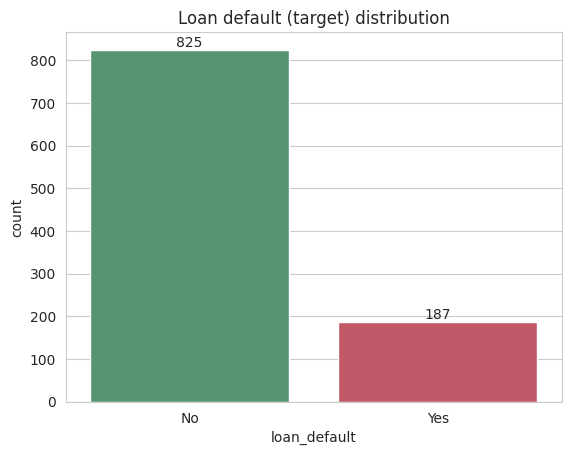

loan_default
No     0.815
Yes    0.185
Name: proportion, dtype: float64


In [6]:
ax = sns.countplot(data=df, x='loan_default', order=['No', 'Yes'], palette=['#4C9F70', '#D1495B'])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.title('Loan default (target) distribution'); plt.show()
print(df['loan_default'].value_counts(normalize=True).round(3))

**Answer:** The target is **imbalanced**: 825 customers repaid (**No, 81.5%**) and 187 defaulted (**Yes, 18.5%**), roughly 4.4 to 1. This matters because (1) accuracy becomes misleading: a model that predicts "No default" for everybody would already be about 81.5% accurate while catching zero defaulters; (2) a tree can drift towards the majority class and neglect the defaulters, who are the ones the bank cares about; so we need recall, F1 and ROC-AUC, and a stratified split to keep the same ratio in train and test.

## Step 3: Clean the data

In [7]:
print('Missing values per column:')
print(df.isnull().sum())

Missing values per column:
customer_id           0
age                   0
income                0
loan_amount           0
credit_score          0
employment_years      0
debt_to_income        0
existing_loans        0
dependents            0
bank_balance          0
interest_rate         0
employment_type       0
marital_status        0
education            61
loan_purpose          0
city_tier             0
previous_defaults     0
loan_default          0
dtype: int64


In [8]:
# Missing categorical values -> label 'Unknown'
df['education'] = df['education'].fillna('Unknown')
print('Missing values left:', df.isnull().sum().sum())
print(df['education'].value_counts())

Missing values left: 0
education
Undergraduate    377
Graduate         276
High School      183
Postgraduate     115
Unknown           61
Name: count, dtype: int64


In [9]:
# Duplicates
print('Exact duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after dropping exact duplicates:', df.shape)

Exact duplicate rows: 11
Shape after dropping exact duplicates: (1001, 18)


In [10]:
# Impossible values
num_cols = df.select_dtypes(include='number').columns
print('Negative values per column:'); print((df[num_cols] < 0).sum()[lambda s: s > 0])
print('\nRows with a negative age:'); display(df[df['age'] < 0][['customer_id', 'age', 'income', 'loan_default']])
print('Rows with a negative income:'); display(df[df['income'] < 0][['customer_id', 'age', 'income', 'loan_default']])
print('Age under 18:', (df['age'] < 18).sum(), '| Credit score above 850:', (df['credit_score'] > 850).sum())

Negative values per column:
age       5
income    5
dtype: int64

Rows with a negative age:


,customer_id,age,income,loan_default
108,CUST00791,-35,61573.0,Yes
237,CUST00050,-22,49113.0,No
458,CUST00713,-46,59189.0,No
579,CUST00943,-52,71028.0,No
885,CUST00286,-39,41597.0,Yes


Rows with a negative income:


,customer_id,age,income,loan_default
16,CUST00088,58,-29071.0,Yes
60,CUST00792,28,-42992.0,No
166,CUST00377,32,-61524.0,Yes
331,CUST00320,23,-62841.0,No
507,CUST00339,26,-74577.0,Yes


Age under 18: 5 | Credit score above 850: 7


In [11]:
# One customer (CUST00050) appears twice: once with age -22 and once with age 22, everything else identical.
# This shows the negatives are sign (typing) errors, so we correct them with abs() instead of throwing away rows.
df['age'] = df['age'].abs()
df['income'] = df['income'].abs()

# Now the sign-corrupted copy of CUST00050 is a true duplicate, so check again
print('Duplicate customer_id values:', df['customer_id'].duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Final shape:', df.shape, '| Negative values left:', (df.select_dtypes('number') < 0).sum().sum())

Duplicate customer_id values: 1
Final shape: (1000, 18) | Negative values left: 0


**Answer:** - **Missing values:** only `education` had missing values (**61 rows, about 6%**). I filled them with the label **'Unknown'**. Education is categorical, so there is no meaningful average. Using the most frequent value would silently label 61 people as Undergraduate, and 'Unknown' keeps every row and lets the model learn if missing education carries any signal.
- **Duplicates:** 11 exact duplicate rows were dropped.
- **Impossible values:** 5 customers had a **negative age** and 5 had a **negative income**. Customer CUST00050 appeared twice, once with age -22 and once with age 22, with every other value identical, which shows these are sign (typing) errors. I fixed them with `abs()` instead of deleting rows; this also exposed that duplicate, which was then removed.
- **Result:** 1,000 clean rows, no missing values, no negatives. Seven credit scores are above 850 (max 900); these are possible on some scoring scales, so I kept them.

## Step 4: Explore the data visually

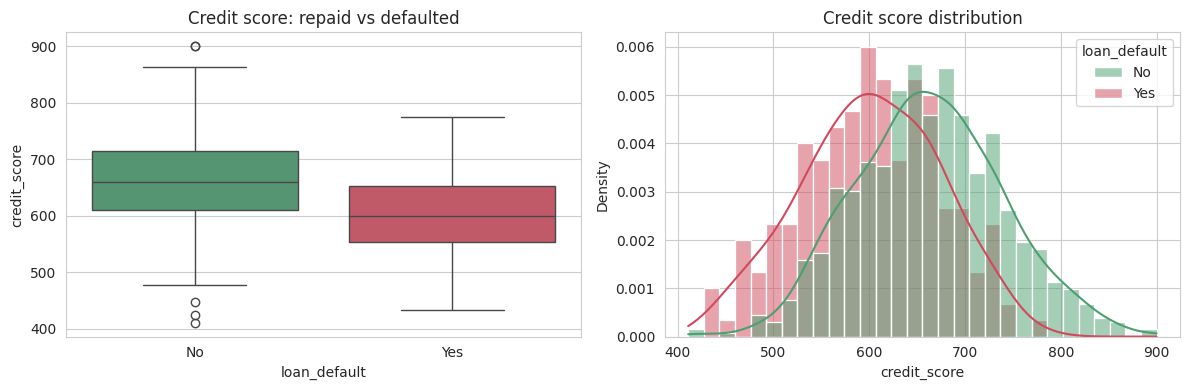

              count   mean   std    min    25%    50%    75%    max
loan_default                                                       
No            816.0  662.7  76.7  411.0  610.8  659.5  714.0  900.0
Yes           184.0  601.5  71.9  433.0  554.0  600.5  653.5  775.0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='loan_default', y='credit_score', order=['No', 'Yes'], palette=['#4C9F70', '#D1495B'], ax=axes[0])
axes[0].set_title('Credit score: repaid vs defaulted')
sns.histplot(data=df, x='credit_score', hue='loan_default', bins=30, kde=True, stat='density', common_norm=False,
             palette={'No': '#4C9F70', 'Yes': '#D1495B'}, ax=axes[1])
axes[1].set_title('Credit score distribution'); plt.tight_layout(); plt.show()
print(df.groupby('loan_default')['credit_score'].describe().round(1))

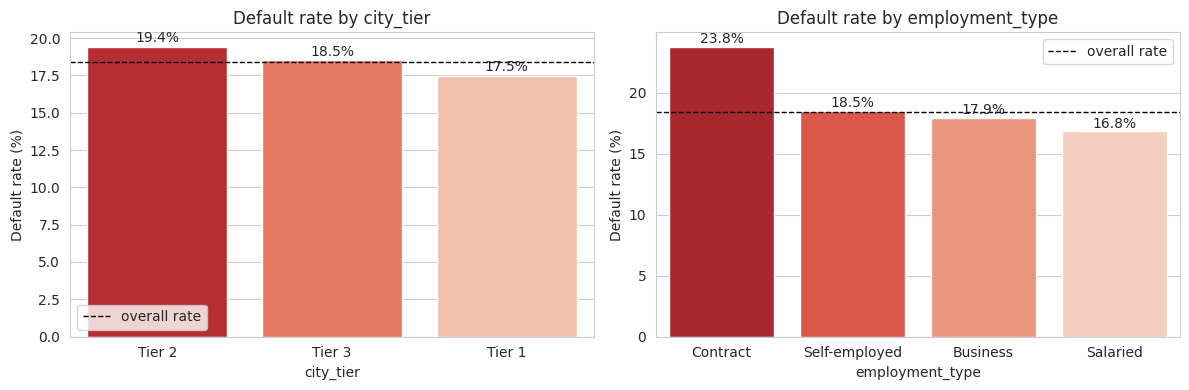

In [13]:
df['default_flag'] = (df['loan_default'] == 'Yes').astype(int)   # helper column for rates / correlation
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['city_tier', 'employment_type']):
    rate = df.groupby(col)['default_flag'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index, y=rate.values, palette='Reds_r', ax=ax)
    ax.axhline(df['default_flag'].mean() * 100, color='k', ls='--', lw=1, label='overall rate')
    for i, v in enumerate(rate.values): ax.text(i, v + 0.3, f'{v:.1f}%', ha='center')
    ax.set_ylabel('Default rate (%)'); ax.set_title(f'Default rate by {col}'); ax.legend()
plt.tight_layout(); plt.show()

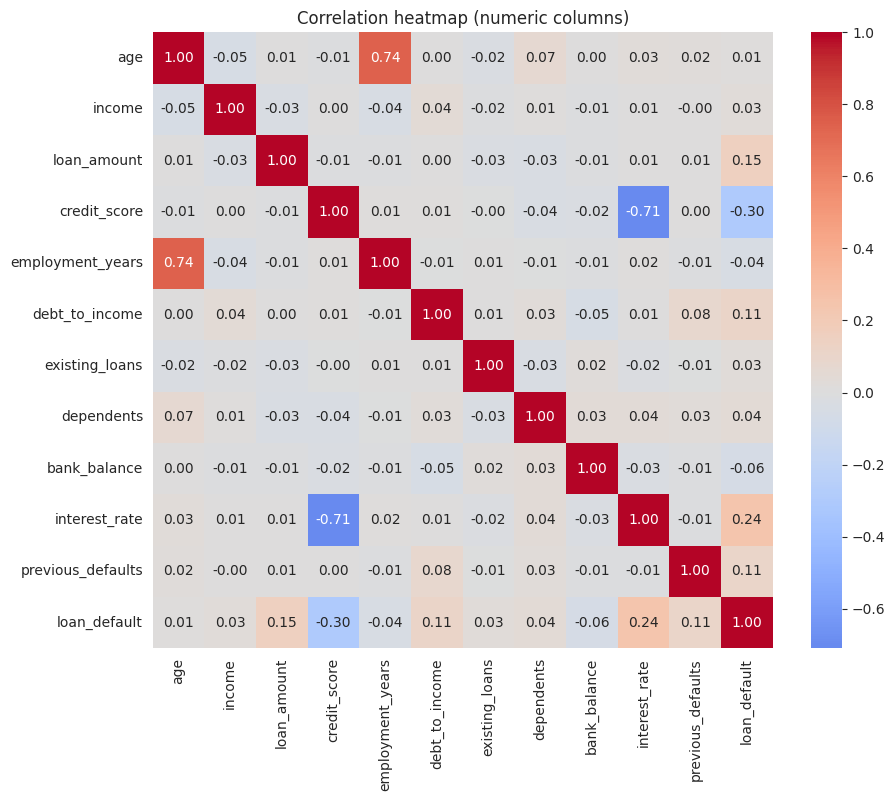

credit_score        -0.299
bank_balance        -0.056
employment_years    -0.036
age                  0.015
existing_loans       0.026
income               0.031
dependents           0.039
previous_defaults    0.106
debt_to_income       0.112
loan_amount          0.153
interest_rate        0.243
Name: loan_default, dtype: float64


In [14]:
num_df = df.select_dtypes(include='number').drop(columns='default_flag').assign(loan_default=df['default_flag'])
plt.figure(figsize=(10, 8))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap (numeric columns)'); plt.show()
print(num_df.corr()['loan_default'].drop('loan_default').sort_values().round(3))

**Answer:** **Credit score** and **interest rate** separate the groups best. Defaulters have clearly lower credit scores (mean about 601 vs 663; correlation with default **-0.30**), and higher interest rates (correlation **+0.24**). Loan amount comes next (+0.15). City tier hardly matters (default rate 17.5% / 19.4% / 18.5%); Contract workers have the highest default rate (23.8% vs about 17-19% for the other types). Overall the correlations are weak, so no single feature separates the classes cleanly.

## Step 5: Prepare the data for modelling

In [15]:
df = df.drop(columns=['customer_id', 'default_flag'])          # drop the id (and the helper column made in Step 4)
df['loan_default'] = df['loan_default'].map({'Yes': 1, 'No': 0})
df = pd.get_dummies(df, drop_first=True)
X = df.drop('loan_default', axis=1); y = df['loan_default']
print('X shape:', X.shape, '| y shape:', y.shape)
print(list(X.columns))

X shape: (1000, 25) | y shape: (1000,)
['age', 'income', 'loan_amount', 'credit_score', 'employment_years', 'debt_to_income', 'existing_loans', 'dependents', 'bank_balance', 'interest_rate', 'previous_defaults', 'employment_type_Contract', 'employment_type_Salaried', 'employment_type_Self-employed', 'marital_status_Married', 'marital_status_Single', 'education_High School', 'education_Postgraduate', 'education_Undergraduate', 'education_Unknown', 'loan_purpose_Education', 'loan_purpose_Home', 'loan_purpose_Personal', 'city_tier_Tier 2', 'city_tier_Tier 3']


**Answer:** A scikit-learn tree makes its splits by comparing numbers (for example `credit_score <= 673.5`). Text such as "Salaried" or "Tier 2" cannot be compared or thresholded, so the strings have to be converted to numbers first. `get_dummies` turns each category into 0/1 columns (and `drop_first=True` removes one redundant column per feature). After encoding there are **25 features**.

## Step 6: Split into training and test sets

In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Training set:', X_train.shape, '| Test set:', X_test.shape)
print('Default rate  train: %.3f  test: %.3f' % (y_train.mean(), y_test.mean()))

Training set: (800, 25) | Test set: (200, 25)
Default rate  train: 0.184  test: 0.185


**Answer:** The split gives **800 training rows and 200 test rows**, with default rates of 18.4% and 18.5% thanks to `stratify=y`. The test set stands in for brand-new customers. If the model were trained on it, it could simply memorise those rows and the scores would look better than they are; keeping it untouched gives an honest estimate of how the model will perform on future applicants.

## Step 7: Train a Decision Tree

In [17]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
train_pred, test_pred = dt.predict(X_train), dt.predict(X_test)
print('Training accuracy:', round(dt.score(X_train, y_train), 4))
print('Test accuracy    :', round(dt.score(X_test, y_test), 4))
print('Tree depth:', dt.get_depth(), '| leaves:', dt.get_n_leaves())
print('Accuracy of always predicting "No default":', round(1 - y_test.mean(), 4))

Training accuracy: 1.0
Test accuracy    : 0.785
Tree depth: 14 | leaves: 117
Accuracy of always predicting "No default": 0.815


**Answer:** Yes, there is a big gap: **training accuracy is 1.000 but test accuracy is only 0.785**, a 21-point difference. The unrestricted tree grew to depth 14 with 117 leaves and memorised the training data, noise included. This is **clear overfitting**. Note also that 0.785 is actually lower than the 0.815 you would get by always predicting "No default".

## Step 8: Evaluate the model properly

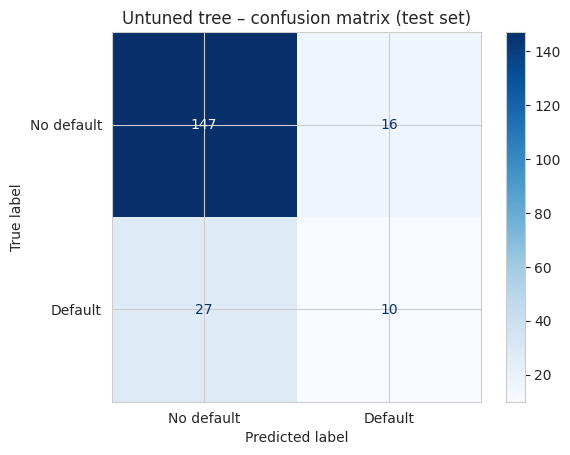

              precision    recall  f1-score   support

  No default       0.84      0.90      0.87       163
     Default       0.38      0.27      0.32        37

    accuracy                           0.79       200
   macro avg       0.61      0.59      0.59       200
weighted avg       0.76      0.79      0.77       200

ROC-AUC: 0.5861


In [18]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, accuracy_score, recall_score, f1_score, roc_curve)
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=['No default', 'Default']).plot(cmap='Blues')
plt.title('Untuned tree – confusion matrix (test set)'); plt.show()
print(classification_report(y_test, test_pred, target_names=['No default', 'Default']))
auc_dt = roc_auc_score(y_test, dt.predict_proba(X_test)[:, 1])
print('ROC-AUC:', round(auc_dt, 4))

**Answer:** On the 200 test customers the untuned tree gives: 147 true negatives, 10 true positives, **16 false positives** (good customers rejected) and **27 false negatives** (defaulters approved). It catches only 27% of defaulters (recall 0.27, precision 0.38, F1 0.32) and the **ROC-AUC is 0.586**, only a little above random guessing (0.5).

**Which error is worse?** Approving a loan that defaults (false negative) is usually worse: the bank can lose the whole principal, whereas rejecting a good customer only loses the interest income. That makes **recall of the Default class** the most important metric (balanced with precision through F1, plus ROC-AUC for overall ranking quality).

## Step 9: Control overfitting by tuning

In [19]:
rows = []
for d in [3, 5, 7, 10]:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    rows.append({'max_depth': d, 'train_acc': m.score(X_train, y_train), 'test_acc': m.score(X_test, y_test),
                 'test_recall': recall_score(y_test, m.predict(X_test)),
                 'test_auc': roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])})
depth_table = pd.DataFrame(rows).set_index('max_depth').round(4)
depth_table

,train_acc,test_acc,test_recall,test_auc
max_depth,,,,
3,0.8338,0.810,0.0270,0.6687
5,0.8712,0.825,0.2162,0.6371
7,0.9112,0.780,0.2162,0.5467
10,0.9812,0.775,0.2432,0.5720


Best parameters : {'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 20}
Best CV ROC-AUC : 0.6925

Tuned tree on the TEST set
Train accuracy: 0.8475 | Test accuracy: 0.78
              precision    recall  f1-score   support

  No default       0.83      0.92      0.87       163
     Default       0.32      0.16      0.21        37

    accuracy                           0.78       200
   macro avg       0.57      0.54      0.54       200
weighted avg       0.73      0.78      0.75       200

ROC-AUC: 0.5807


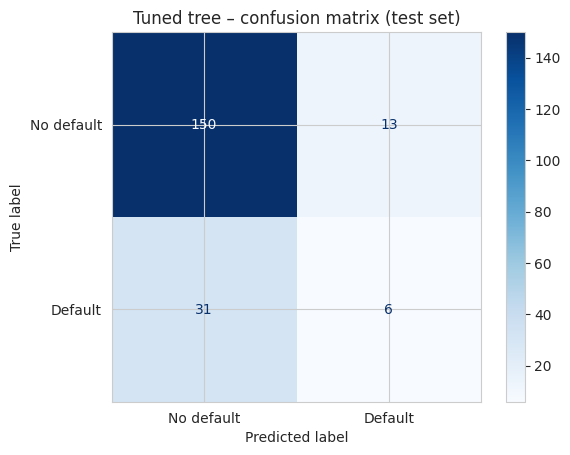

In [20]:
from sklearn.model_selection import GridSearchCV
param_grid = {'max_depth': [3, 4, 5, 6, 7, 8, 10, None],
              'min_samples_leaf': [1, 5, 10, 20, 30],
              'criterion': ['gini', 'entropy']}
# scoring='roc_auc': with only ~18% defaulters, plain accuracy would reward a tree that predicts "No" for everyone
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)
print('Best parameters :', grid.best_params_)
print('Best CV ROC-AUC :', round(grid.best_score_, 4))

best = grid.best_estimator_
best_pred = best.predict(X_test)
print('\nTuned tree on the TEST set')
print('Train accuracy:', round(best.score(X_train, y_train), 4), '| Test accuracy:', round(best.score(X_test, y_test), 4))
print(classification_report(y_test, best_pred, target_names=['No default', 'Default']))
auc_best = roc_auc_score(y_test, best.predict_proba(X_test)[:, 1])
print('ROC-AUC:', round(auc_best, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred), display_labels=['No default', 'Default']).plot(cmap='Blues')
plt.title('Tuned tree – confusion matrix (test set)'); plt.show()

**Answer:** - By **test accuracy**, **max_depth = 5** was best (0.825), but that is barely above the 0.815 "always No" baseline. Depth 3 also scored 0.810 accuracy but with a recall of only 0.03, i.e. it almost never predicts a default. By ROC-AUC, depth 3 was best (0.669), and deeper trees (7 and 10) overfit more (train 0.91 and 0.98, test AUC falls to about 0.55-0.57).
- **GridSearchCV** chose `criterion='entropy'`, `max_depth=8`, `min_samples_leaf=20` (cross-validated ROC-AUC 0.69).
- **Compared with Step 7:** the overfitting went down a lot (train 0.848 vs test 0.780, a gap of about 7 points instead of 21), so the tree is far more stable and simpler. However, the test scores did **not** improve: accuracy 0.785 to 0.780, recall 0.27 to 0.16, ROC-AUC 0.586 to 0.581. The tuning removed memorisation, but the features simply do not contain much signal for a tree to use. (The test set has only 37 defaulters, so these numbers are noisy.)

## Step 10: Compare with a baseline model

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler().fit(X_train)                       # fit on the training data only
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_s, y_train)

def scores(name, model, Xte):
    p = model.predict(Xte)
    return {'Model': name, 'Accuracy': accuracy_score(y_test, p), 'Recall': recall_score(y_test, p),
            'F1': f1_score(y_test, p), 'ROC-AUC': roc_auc_score(y_test, model.predict_proba(Xte)[:, 1])}

comparison = pd.DataFrame([scores('Logistic Regression', lr, X_test_s),
                           scores('Decision Tree (untuned)', dt, X_test),
                           scores('Decision Tree (tuned)', best, X_test)]).set_index('Model').round(3)
comparison

,Accuracy,Recall,F1,ROC-AUC
Model,,,,
Logistic Regression,0.835,0.243,0.353,0.774
Decision Tree (untuned),0.785,0.270,0.317,0.586
Decision Tree (tuned),0.780,0.162,0.214,0.581


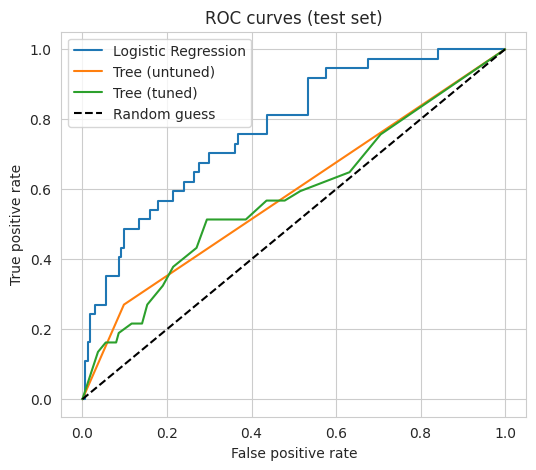

In [22]:
plt.figure(figsize=(6, 5))
for name, model, Xte in [('Logistic Regression', lr, X_test_s), ('Tree (untuned)', dt, X_test), ('Tree (tuned)', best, X_test)]:
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(Xte)[:, 1]); plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], 'k--', label='Random guess'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('ROC curves (test set)'); plt.legend(); plt.show()

**Answer:** I would recommend **Logistic Regression**. It has the best accuracy (0.835), F1 (0.353) and by far the best ROC-AUC (0.774 vs about 0.58 for both trees), and its recall (0.24) is similar to the untuned tree's, which only reaches 0.27 by overfitting. It is simple, stable, and outputs default probabilities, so the bank can **lower the approval threshold** (for example flag anyone above 20% default probability) to catch more defaulters. Its weakness is that recall is still low at the default 0.5 threshold, and the tree's only advantage is that its rules are easier to read.

## Step 11: Interpret the model

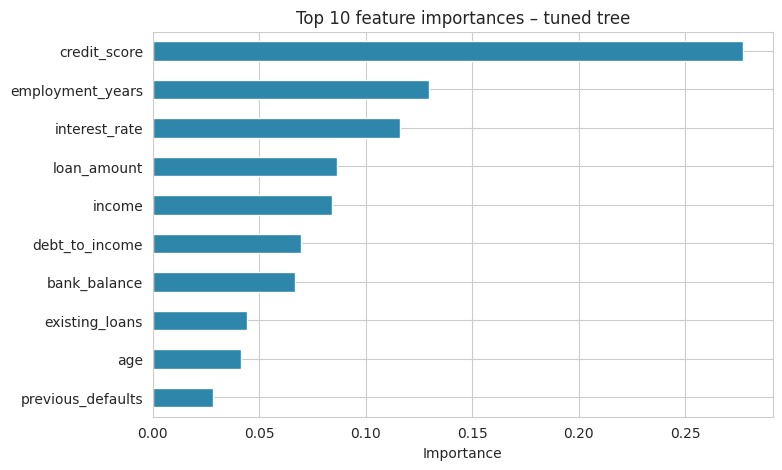

credit_score         0.277
employment_years     0.130
interest_rate        0.116
loan_amount          0.086
income               0.084
debt_to_income       0.069
bank_balance         0.067
existing_loans       0.044
age                  0.042
previous_defaults    0.028
dtype: float64


In [23]:
imp = pd.Series(best.feature_importances_, index=X.columns).nlargest(10)
imp.sort_values().plot(kind='barh', color='#2E86AB', figsize=(8, 5))
plt.title('Top 10 feature importances – tuned tree'); plt.xlabel('Importance'); plt.show()
print(imp.round(3))

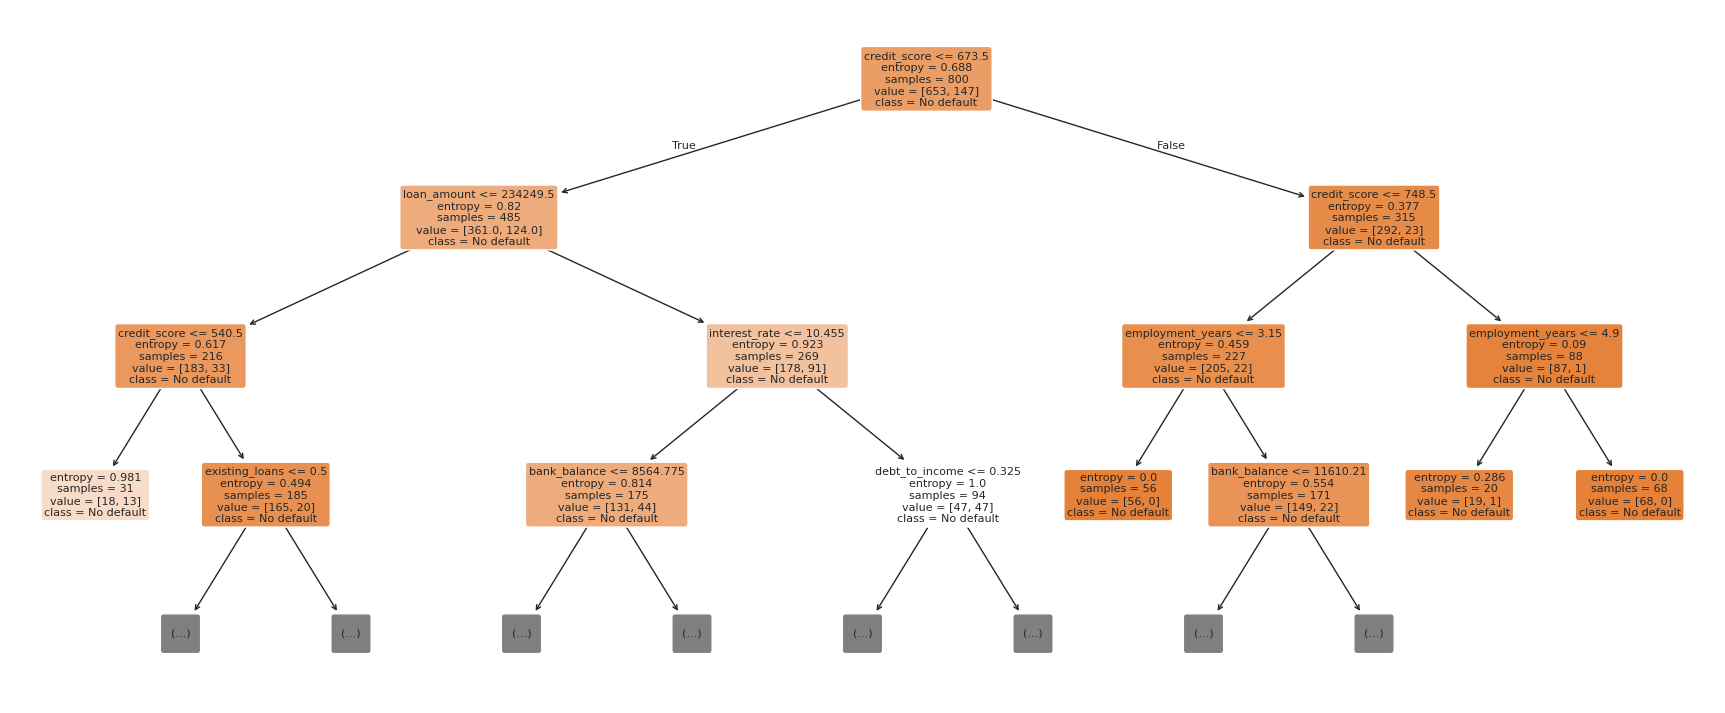

|--- credit_score <= 673.50
|   |--- loan_amount <= 234249.50
|   |   |--- credit_score <= 540.50
|   |   |   |--- class: 0
|   |   |--- credit_score >  540.50
|   |   |   |--- truncated branch of depth 5
|   |--- loan_amount >  234249.50
|   |   |--- interest_rate <= 10.45
|   |   |   |--- truncated branch of depth 5
|   |   |--- interest_rate >  10.45
|   |   |   |--- truncated branch of depth 3
|--- credit_score >  673.50
|   |--- credit_score <= 748.50
|   |   |--- employment_years <= 3.15
|   |   |   |--- class: 0
|   |   |--- employment_years >  3.15
|   |   |   |--- truncated branch of depth 5
|   |--- credit_score >  748.50
|   |   |--- employment_years <= 4.90
|   |   |   |--- class: 0
|   |   |--- employment_years >  4.90
|   |   |   |--- class: 0



In [24]:
from sklearn.tree import plot_tree, export_text
plt.figure(figsize=(22, 9))
plot_tree(best, max_depth=3, feature_names=X.columns, class_names=['No default', 'Default'], filled=True, rounded=True, fontsize=8)
plt.show()
print(export_text(best, feature_names=list(X.columns), max_depth=2))

**Answer:** **Top five features (tuned tree):** 1) `credit_score` (0.28), 2) `employment_years` (0.13), 3) `interest_rate` (0.12), 4) `loan_amount` (0.09), 5) `income` (0.08).

**Match with Step 4:** partly. `credit_score`, `interest_rate` and `loan_amount` were also the strongest in the correlation analysis. But `employment_years` and `income` had almost no correlation with default (-0.04 and +0.03), and `previous_defaults` / `debt_to_income` looked more related to default than their tree rank suggests. A tree can use a feature through non-linear splits, but some of this is probably noise fitted by the tree.

**Two decision rules (from the tuned tree):**
1. If the customer has a **credit score of 673 or below, a loan above about 234,000, an interest rate above 10.45%, debt-to-income above 0.33 and at most 2 dependents**, the tree predicts **Default**. In training, 24 of the 31 customers in this group defaulted (about 77%).
2. If the customer has a **credit score above 748 and more than 4.9 years of employment**, the tree predicts **No default**. All 68 training customers in this group repaid.

## Step 12: Conclusion

**Answer:** We built a model to flag loan applicants likely to default, using 1,000 cleaned customer records. The model works well at recognising **safe customers**: the tuned tree correctly approves about 92% of the people who repay, and it shows that **credit score is the strongest warning sign**, followed by interest rate and loan amount. Its main limitation is that it **misses most defaulters** (recall is only 0.16, ROC-AUC 0.58, hardly better than guessing), and the tuned tree scores below a simple Logistic Regression (AUC 0.77) and below the 81.5% accuracy of just saying "no default" for everyone, so it should not be used alone to make lending decisions. The dataset is small and imbalanced (only 187 defaulters), and the test set holds just 37 of them, so all results are noisy. The one thing I would do to improve it is **collect more data, particularly more defaulter cases and richer repayment-history features**, because none of the models, including a Random Forest, can find much signal in the current 1,000 rows.

## Extra: Random Forest vs tuned Decision Tree

,Accuracy,Recall,F1,ROC-AUC
Model,,,,
Logistic Regression,0.835,0.243,0.353,0.774
Decision Tree (tuned),0.780,0.162,0.214,0.581
Random Forest,0.820,0.108,0.182,0.704


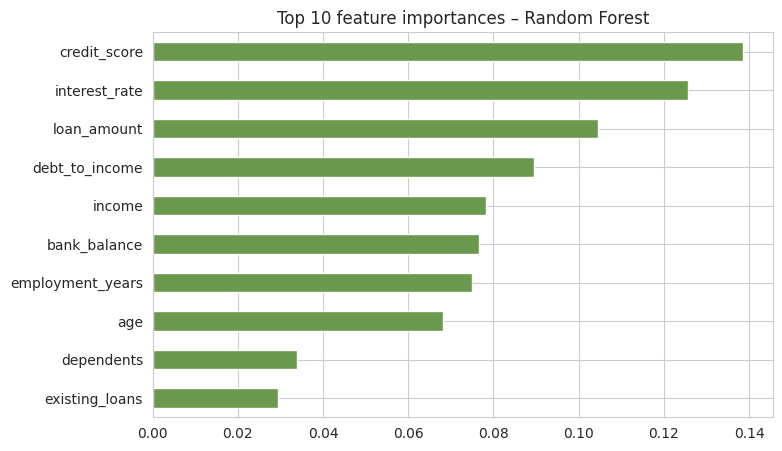

In [25]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_train, y_train)
extra = pd.DataFrame([scores('Logistic Regression', lr, X_test_s), scores('Decision Tree (tuned)', best, X_test),
                      scores('Random Forest', rf, X_test)]).set_index('Model').round(3)
display(extra)
pd.Series(rf.feature_importances_, index=X.columns).nlargest(10).sort_values().plot(kind='barh', color='#6A994E', figsize=(8, 5))
plt.title('Top 10 feature importances – Random Forest'); plt.show()

**Answer:** The Random Forest improves on the tuned tree in accuracy (0.820 vs 0.780) and ROC-AUC (0.704 vs 0.581), because averaging many trees reduces variance. But its recall for defaulters is the lowest of the three (0.108) and it still trails Logistic Regression on AUC (0.774) and F1. So on this small, noisy dataset, a more complex model does not solve the problem; more and better data would help more.